
# Stallaris — A Tiny Language Model Trained on NASA Space Data

## 1. Introduction

ORION is an educational language-modeling project that explores how a small Transformer-based language model can learn patterns from space-related textual data.

The model is trained **from scratch using PyTorch**, without pretrained language models, external AI APIs, or hosted inference services.

The objective is not to build a production-grade conversational AI system. Instead, the project focuses on understanding the fundamental components behind modern language models, including tokenization, embeddings, attention mechanisms, Transformer architecture, model training, and autoregressive text generation.

## 2. Project Objectives

1. Load and explore NASA-related datasets.
2. Clean and combine structured data into a training corpus.
3. Build a custom tokenizer without pretrained vocabulary.
4. Prepare training sequences using sliding context windows.
5. Implement a decoder-only Transformer language model.
6. Train the model using next-token prediction.
7. Evaluate learning using training loss, validation loss, and perplexity.
8. Generate new text through autoregressive sampling.

## 3. Technology Stack

- **Programming Language:** Python
- **Deep Learning Framework:** PyTorch
- **Data Processing:** Pandas, NumPy
- **Visualization:** Matplotlib
- **Model Architecture:** Decoder-only Transformer
- **Training Strategy:** Next-token prediction
- **Dataset:** NASA and space-related datasets

## 4. Learning Approach

The model begins with randomly initialized parameters and gradually learns statistical patterns from the training corpus.

Given a sequence of tokens, it learns to predict the next token. During generation, previously generated tokens are repeatedly fed back into the model to produce a continuation.

This project demonstrates the core mechanics of a small language model while highlighting the computational and data limitations of training language models from scratch on relatively small datasets.


In [2]:

# ============================================================
# 2. IMPORTS AND ENVIRONMENT SETUP
# ============================================================

import os
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# Hardware detection
# ------------------------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("STALLARIS — Environment Information")
print("-" * 45)
print("Python environment initialized.")
print("PyTorch version:", torch.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Selected device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / (1024**3), 2),
          "GB")
else:
    print("GPU unavailable. Training will use CPU.")

print("-" * 45)


STALLARIS — Environment Information
---------------------------------------------
Python environment initialized.
PyTorch version: 2.6.0+cu124
NumPy version: 1.26.4
Pandas version: 2.2.3
Selected device: cpu
GPU unavailable. Training will use CPU.
---------------------------------------------



# 3. Dataset Loading and Exploration

The quality and structure of the training data directly influence what a language model can learn.

Stallaris uses space-related datasets containing information about NASA missions, extravehicular activities, and near-Earth objects.

Before training, we will inspect the available datasets, understand their columns and dimensions, and identify the files suitable for constructing our text corpus.

### Objectives

- Locate the available input datasets.
- Load the relevant CSV files using Pandas.
- Inspect their dimensions, columns, and sample records.
- Identify missing values and data types.
- Determine which datasets can contribute useful text to the training corpus.

We will examine the data before deciding how to combine and preprocess it.


In [3]:

input_dir = "/kaggle/input"

if not os.path.exists(input_dir):
    raise FileNotFoundError("Kaggle input directory not found.")

csv_files = []

for root, dirs, files in os.walk(input_dir):
    for file in files:
        if file.lower().endswith(".csv"):
            path = os.path.join(root, file)
            csv_files.append(path)

print("Available CSV datasets:")
print("-" * 60)

for i, path in enumerate(csv_files, 1):
    size_mb = os.path.getsize(path) / (1024 ** 2)
    print(f"{i}. {path} ({size_mb:.2f} MB)")

print("-" * 60)
print("Total CSV files found:", len(csv_files))

if not csv_files:
    print("No CSV files found. Check the Kaggle dataset attachments.")


Available CSV datasets:
------------------------------------------------------------
1. /kaggle/input/created-data/space_dataset_merged.csv (0.07 MB)
2. /kaggle/input/nasa-training/cleaned_5250.csv (0.49 MB)
3. /kaggle/input/nasa-training/eva.csv (0.09 MB)
4. /kaggle/input/nasa-training/nearest-earth-objects(1910-2024).csv (32.18 MB)
5. /kaggle/input/nasa-training/neo.csv (9.04 MB)
6. /kaggle/input/nasa-training/neo_v2.csv (9.04 MB)
------------------------------------------------------------
Total CSV files found: 6



# 4. Inspecting the Available Datasets

The notebook currently has six CSV files available:

| Dataset | Size | Description |
|---|---:|---|
| space_dataset_merged.csv | 0.07 MB | Previously combined space-related data |
| cleaned_5250.csv | 0.49 MB | Cleaned dataset containing 5,250 records |
| eva.csv | 0.09 MB | Extravehicular activity data |
| nearest-earth-objects(1910-2024).csv | 32.18 MB | Near-Earth object records |
| neo.csv | 9.04 MB | Near-Earth object data |
| neo_v2.csv | 9.04 MB | Another version of Near-Earth object data |

We will examine the structure of these files before selecting our training sources.

Special attention will be given to:
- Column names and data types.
- Number of records.
- Missing values.
- Sample records.
- Potential overlap between datasets.

The goal is to construct a useful text corpus rather than simply combine every available CSV file.


In [4]:

datasets = {}

for path in csv_files:
    name = os.path.splitext(os.path.basename(path))[0]

    try:
        df = pd.read_csv(path, low_memory=False)
        datasets[name] = df

        print(f"\n{'=' * 70}")
        print(f"DATASET: {name}")
        print(f"{'=' * 70}")

        print("Shape:", df.shape)
        print("\nColumns:")
        print(df.columns.tolist())

        print("\nData types:")
        print(df.dtypes)

        print("\nMissing values:")
        print(df.isnull().sum())

        print("\nSample records:")
        display(df.head(3))

    except Exception as e:
        print(f"Could not load {name}: {e}")

print("\nSuccessfully loaded datasets:", len(datasets))



DATASET: space_dataset_merged
Shape: (748, 2)

Columns:
['prompt', 'response']

Data types:
prompt      object
response    object
dtype: object

Missing values:
prompt      0
response    0
dtype: int64

Sample records:


,prompt,response
0,Earth,Earth is the third planet from the Sun and the...
1,Mars,Mars is a cold desert world often called the R...
2,Jupiter,Jupiter is the largest planet in our solar sys...



DATASET: cleaned_5250
Shape: (5250, 13)

Columns:
['name', 'distance', 'stellar_magnitude', 'planet_type', 'discovery_year', 'mass_multiplier', 'mass_wrt', 'radius_multiplier', 'radius_wrt', 'orbital_radius', 'orbital_period', 'eccentricity', 'detection_method']

Data types:
name                  object
distance             float64
stellar_magnitude    float64
planet_type           object
discovery_year         int64
mass_multiplier      float64
mass_wrt              object
radius_multiplier    float64
radius_wrt            object
orbital_radius       float64
orbital_period       float64
eccentricity         float64
detection_method      object
dtype: object

Missing values:
name                   0
distance              17
stellar_magnitude    161
planet_type            0
discovery_year         0
mass_multiplier       23
mass_wrt              23
radius_multiplier     17
radius_wrt            17
orbital_radius       289
orbital_period         0
eccentricity           0
detection_metho

,name,distance,stellar_magnitude,planet_type,discovery_year,mass_multiplier,mass_wrt,radius_multiplier,radius_wrt,orbital_radius,orbital_period,eccentricity,detection_method
0,11 Comae Berenices b,304.0,4.72307,Gas Giant,2007,19.40,Jupiter,1.08,Jupiter,1.29,0.892539,0.23,Radial Velocity
1,11 Ursae Minoris b,409.0,5.01300,Gas Giant,2009,14.74,Jupiter,1.09,Jupiter,1.53,1.400000,0.08,Radial Velocity
2,14 Andromedae b,246.0,5.23133,Gas Giant,2008,4.80,Jupiter,1.15,Jupiter,0.83,0.508693,0.00,Radial Velocity



DATASET: eva
Shape: (374, 7)

Columns:
['EVA #', 'Country', 'Crew', 'Vehicle', 'Date', 'Duration', 'Purpose']

Data types:
EVA #       float64
Country      object
Crew         object
Vehicle      object
Date         object
Duration     object
Purpose      object
dtype: object

Missing values:
EVA #       4
Country     0
Crew        0
Vehicle     1
Date        0
Duration    1
Purpose     4
dtype: int64

Sample records:


,EVA #,Country,Crew,Vehicle,Date,Duration,Purpose
0,1.0,USA,Ed White,Gemini IV,06/03/1965,0:36,First U.S. EVA. Used HHMU and took photos. G...
1,2.0,USA,David Scott,Gemini VIII,"March 16-17, 1966",0:00,HHMU EVA cancelled before starting by stuck on...
2,3.0,USA,Eugene Cernan,Gemini IX-A,06/05/1966,2:07,"Inadequate restraints, stiff 25ft umbilical an..."


... (3 outputs left out)

,id,name,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,orbiting_body,sentry_object,absolute_magnitude,hazardous
0,2162635,162635 (2000 SS164),1.198271,2.679415,13569.249224,5.483974e+07,Earth,False,16.73,False
1,2277475,277475 (2005 WK4),0.265800,0.594347,73588.726663,6.143813e+07,Earth,False,20.00,True
2,2512244,512244 (2015 YE18),0.722030,1.614507,114258.692129,4.979872e+07,Earth,False,17.83,False



DATASET: neo_v2
Shape: (90836, 10)

Columns:
['id', 'name', 'est_diameter_min', 'est_diameter_max', 'relative_velocity', 'miss_distance', 'orbiting_body', 'sentry_object', 'absolute_magnitude', 'hazardous']

Data types:
id                      int64
name                   object
est_diameter_min      float64
est_diameter_max      float64
relative_velocity     float64
miss_distance         float64
orbiting_body          object
sentry_object            bool
absolute_magnitude    float64
hazardous                bool
dtype: object

Missing values:
id                    0
name                  0
est_diameter_min      0
est_diameter_max      0
relative_velocity     0
miss_distance         0
orbiting_body         0
sentry_object         0
absolute_magnitude    0
hazardous             0
dtype: int64

Sample records:


,id,name,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,orbiting_body,sentry_object,absolute_magnitude,hazardous
0,2162635,162635 (2000 SS164),1.198271,2.679415,13569.249224,5.483974e+07,Earth,False,16.73,False
1,2277475,277475 (2005 WK4),0.265800,0.594347,73588.726663,6.143813e+07,Earth,False,20.00,True
2,2512244,512244 (2015 YE18),0.722030,1.614507,114258.692129,4.979872e+07,Earth,False,17.83,False



Successfully loaded datasets: 6



# 5. Dataset Selection Strategy

The inspection revealed that the available datasets contain different types of information.

Some datasets contain natural-language descriptions, while others contain primarily numerical and categorical information.

For Stallaris, we will use a combination of these sources to construct a diverse space-related training corpus.

### Selected Sources

1. **Space Knowledge:** Existing prompt-response pairs describing planets and space-related topics.
2. **Exoplanet Data:** Planetary properties such as mass, radius, orbital period, and discovery method.
3. **Extravehicular Activities:** Historical spacewalk records, crew information, and mission purposes.
4. **Near-Earth Objects:** Asteroid properties, estimated diameters, relative velocities, and miss distances.

### Data Selection Considerations

- Duplicate datasets should not be included unnecessarily.
- Numerical records must be converted into readable text.
- Missing values must be handled carefully.
- Dataset sources should remain distinguishable during preprocessing.

The objective is to produce a consistent text corpus containing both descriptive knowledge and structured scientific information.


In [5]:

neo = datasets["neo"]
neo_v2 = datasets["neo_v2"]
neo_large = datasets["nearest-earth-objects(1910-2024)"]

print("NEO DATASET COMPARISON")
print("=" * 55)

print("neo and neo_v2 have identical contents:",
      neo.equals(neo_v2))

print("\nRecord counts:")
print("NEO:", len(neo))
print("NEO v2:", len(neo_v2))
print("Large NEO:", len(neo_large))

print("\nDuplicate IDs:")
print("NEO duplicate IDs:", neo["id"].duplicated().sum())
print("NEO v2 duplicate IDs:", neo_v2["id"].duplicated().sum())
print("Large NEO duplicate IDs:", neo_large["neo_id"].duplicated().sum())

neo_ids = set(neo["id"].astype(str))
large_neo_ids = set(neo_large["neo_id"].astype(str))

common_ids = neo_ids.intersection(large_neo_ids)

print("\nOverlap between NEO and Large NEO:")
print("Common IDs:", len(common_ids))
print("NEO records:", len(neo_ids))
print("Large NEO records:", len(large_neo_ids))

print("\nNEO dataset sample:")
display(neo.head(3))


NEO DATASET COMPARISON
neo and neo_v2 have identical contents: True

Record counts:
NEO: 90836
NEO v2: 90836
Large NEO: 338199

Duplicate IDs:
NEO duplicate IDs: 63413
NEO v2 duplicate IDs: 63413
Large NEO duplicate IDs: 304685

Overlap between NEO and Large NEO:
Common IDs: 25792
NEO records: 27423
Large NEO records: 33514

NEO dataset sample:


,id,name,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,orbiting_body,sentry_object,absolute_magnitude,hazardous
0,2162635,162635 (2000 SS164),1.198271,2.679415,13569.249224,5.483974e+07,Earth,False,16.73,False
1,2277475,277475 (2005 WK4),0.265800,0.594347,73588.726663,6.143813e+07,Earth,False,20.00,True
2,2512244,512244 (2015 YE18),0.722030,1.614507,114258.692129,4.979872e+07,Earth,False,17.83,False



# 6. Final Dataset Selection and Deduplication

The dataset comparison identified significant duplication in the Near-Earth Object datasets.

The `neo` and `neo_v2` datasets contain identical records. The larger `nearest-earth-objects(1910-2024)` dataset also contains repeated asteroid IDs.

To prevent repeated records from disproportionately influencing model training, we will use the following strategy:

### Selected Datasets

| Dataset | Processing Strategy |
|---|---|
| space_dataset_merged | Retain prompt-response pairs |
| cleaned_5250 | Retain exoplanet records |
| eva | Retain spacewalk records |
| nearest-earth-objects(1910-2024) | Remove repeated asteroid IDs |

### Excluded Datasets

- `neo`: Excluded because the larger NEO dataset provides overlapping information.
- `neo_v2`: Excluded because it is identical to `neo`.

For the initial corpus, repeated asteroid IDs will be reduced to one representative record using the first available occurrence.

This approach reduces redundancy and produces a more manageable dataset for language-model training.


In [6]:

space_df = datasets["space_dataset_merged"].copy()
exoplanet_df = datasets["cleaned_5250"].copy()
eva_df = datasets["eva"].copy()
neo_df = datasets["nearest-earth-objects(1910-2024)"].copy()

neo_df = neo_df.drop_duplicates(subset="neo_id", keep="first")

selected_datasets = {
    "space": space_df,
    "exoplanets": exoplanet_df,
    "eva": eva_df,
    "neo": neo_df
}

print("FINAL DATASET SUMMARY")
print("=" * 55)

total_records = 0

for name, df in selected_datasets.items():
    print(f"{name:15} | {len(df):>8,} records | {len(df.columns)} columns")
    total_records += len(df)

print("-" * 55)
print(f"{'Total':15} | {total_records:>8,} records")

print("\nRemaining duplicate NEO IDs:",
      neo_df["neo_id"].duplicated().sum())

print("\nSelected datasets successfully prepared.")


FINAL DATASET SUMMARY
space           |      748 records | 2 columns
exoplanets      |    5,250 records | 13 columns
eva             |      374 records | 7 columns
neo             |   33,514 records | 9 columns
-------------------------------------------------------
Total           |   39,886 records

Remaining duplicate NEO IDs: 0

Selected datasets successfully prepared.



# 7. Text Corpus Construction

A Transformer language model learns from sequences of tokens rather than directly understanding CSV tables.

Therefore, the selected datasets must be transformed into a consistent textual representation before tokenization and training.

We will construct the Stallaris corpus using four categories of information.

### 1. General Space Knowledge

Existing prompt-response pairs will be converted into question-and-answer text.

### 2. Exoplanet Information

Planetary records will be transformed into descriptive sentences containing available information such as:
- Planet name and type.
- Discovery year.
- Distance from Earth.
- Mass and radius.
- Orbital radius and period.
- Detection method.

### 3. Extravehicular Activities

Spacewalk records will be represented using crew, country, spacecraft, date, duration, and mission purpose.

### 4. Near-Earth Objects

Asteroid records will be converted into factual descriptions containing:
- Object name and identifier.
- Estimated diameter.
- Relative velocity.
- Miss distance.
- Absolute magnitude.
- Hazard classification.

### Text Normalization

Missing values will be handled without inserting misleading information. Numerical values will be formatted for readability, and each record will be separated clearly.

The resulting corpus will combine descriptive knowledge and structured scientific information into a single text sequence suitable for language-model training.


In [7]:

def clean_value(value):
    if pd.isna(value):
        return None
    if isinstance(value, (float, np.floating)):
        return f"{value:.4f}".rstrip("0").rstrip(".")
    return str(value).strip()


text_documents = []

# General space knowledge
for _, row in space_df.iterrows():
    prompt = clean_value(row["prompt"])
    response = clean_value(row["response"])

    if prompt and response:
        text_documents.append(
            f"Question: {prompt}\nAnswer: {response}"
        )

# Exoplanet records
for _, row in exoplanet_df.iterrows():
    fields = {
        "Name": row["name"],
        "Planet type": row["planet_type"],
        "Distance": row["distance"],
        "Stellar magnitude": row["stellar_magnitude"],
        "Discovery year": row["discovery_year"],
        "Mass": f'{clean_value(row["mass_multiplier"])} {clean_value(row["mass_wrt"])}',
        "Radius": f'{clean_value(row["radius_multiplier"])} {clean_value(row["radius_wrt"])}',
        "Orbital radius": row["orbital_radius"],
        "Orbital period": row["orbital_period"],
        "Eccentricity": row["eccentricity"],
        "Detection method": row["detection_method"]
    }

    details = [
        f"{key}: {clean_value(value)}"
        for key, value in fields.items()
        if clean_value(value) is not None
    ]

    text_documents.append(
        "Exoplanet information. " + ". ".join(details) + "."
    )

# Extravehicular activity records
for _, row in eva_df.iterrows():
    fields = {
        "EVA number": row["EVA #"],
        "Country": row["Country"],
        "Crew": row["Crew"],
        "Vehicle": row["Vehicle"],
        "Date": row["Date"],
        "Duration": row["Duration"],
        "Purpose": row["Purpose"]
    }

    details = [
        f"{key}: {clean_value(value)}"
        for key, value in fields.items()
        if clean_value(value) is not None
    ]

    text_documents.append(
        "Extravehicular activity record. " + ". ".join(details) + "."
    )

# Near-Earth object records
for _, row in neo_df.iterrows():
    fields = {
        "Object ID": row["neo_id"],
        "Object name": row["name"],
        "Absolute magnitude": row["absolute_magnitude"],
        "Minimum diameter": row["estimated_diameter_min"],
        "Maximum diameter": row["estimated_diameter_max"],
        "Orbiting body": row["orbiting_body"],
        "Relative velocity": row["relative_velocity"],
        "Miss distance": row["miss_distance"],
        "Potentially hazardous": row["is_hazardous"]
    }

    details = [
        f"{key}: {clean_value(value)}"
        for key, value in fields.items()
        if clean_value(value) is not None
    ]

    text_documents.append(
        "Near-Earth object information. " + ". ".join(details) + "."
    )

print("Text document construction completed.")
print("Total documents:", len(text_documents))
print("\nSample documents:\n")

for i, document in enumerate(text_documents[:5], 1):
    print(f"DOCUMENT {i}")
    print(document)
    print("-" * 70)


Text document construction completed.
Total documents: 39886

Sample documents:

DOCUMENT 1
Question: Earth
Answer: Earth is the third planet from the Sun and the only one known to support life.
----------------------------------------------------------------------
DOCUMENT 2
Question: Mars
Answer: Mars is a cold desert world often called the Red Planet because of its reddish soil.
----------------------------------------------------------------------
DOCUMENT 3
Question: Jupiter
Answer: Jupiter is the largest planet in our solar system and has a giant storm called the Great Red Spot.
----------------------------------------------------------------------
DOCUMENT 4
Question: Saturn
Answer: Saturn is famous for its bright rings made of ice and rock.
----------------------------------------------------------------------
DOCUMENT 5
Question: Venus
Answer: Venus is covered by thick clouds and has a very hot surface, hotter than Mercury.
-----------------------------------------------------


# 8. Corpus Preparation and Text Normalization

After converting the selected datasets into individual text documents, the next step is to construct a unified training corpus.

A language model requires a continuous sequence of text that can later be divided into tokens and training sequences.

### Processing Steps

1. Remove empty documents.
2. Normalize unnecessary whitespace.
3. Preserve meaningful punctuation and numerical information.
4. Combine documents using clear separation markers.
5. Calculate corpus statistics, including character count and document length.

Each document will remain separated by a newline boundary to reduce accidental merging between unrelated records.

The resulting corpus will serve as the input to our custom tokenizer.


In [8]:

cleaned_documents = []

for document in text_documents:
    document = " ".join(document.split())

    if document:
        cleaned_documents.append(document)

text_corpus = "\n\n".join(cleaned_documents)

document_lengths = [len(doc) for doc in cleaned_documents]

print("STALLARIS — CORPUS STATISTICS")
print("=" * 50)
print("Original documents:", len(text_documents))
print("Cleaned documents:", len(cleaned_documents))
print("Total characters:", f"{len(text_corpus):,}")
print("Average document length:", f"{np.mean(document_lengths):.2f}")
print("Shortest document:", min(document_lengths))
print("Longest document:", max(document_lengths))
print("Total corpus size (MB):",
      f"{len(text_corpus.encode('utf-8')) / (1024**2):.3f}")

print("\nCorpus preview:\n")
print(text_corpus[:1500])


STALLARIS — CORPUS STATISTICS
Original documents: 39886
Cleaned documents: 39886
Total characters: 10,630,617
Average document length: 264.53
Shortest document: 76
Longest document: 807
Total corpus size (MB): 10.138

Corpus preview:

Question: Earth Answer: Earth is the third planet from the Sun and the only one known to support life.

Question: Mars Answer: Mars is a cold desert world often called the Red Planet because of its reddish soil.

Question: Jupiter Answer: Jupiter is the largest planet in our solar system and has a giant storm called the Great Red Spot.

Question: Saturn Answer: Saturn is famous for its bright rings made of ice and rock.

Question: Venus Answer: Venus is covered by thick clouds and has a very hot surface, hotter than Mercury.

Question: Mercury Answer: Mercury is the smallest planet and the closest one to the Sun.

Question: Neptune Answer: Neptune is a blue planet with strong winds and storms, located far from the Sun.

Question: Uranus Answer: Uranus rot


# 9. Corpus Analysis and Distribution

Before tokenization, we will examine the composition of the training corpus.

Although all four datasets have been combined, their contributions are not equally distributed.

The Near-Earth Object dataset contains substantially more records than the other sources. Consequently, it may dominate the training process.

### Analysis Objectives

- Measure the contribution of each dataset.
- Examine document-length distribution.
- Identify potential imbalance in the training material.
- Understand the vocabulary and character distribution.

These observations will help guide tokenizer design and subsequent training decisions.

We will preserve the original scientific information while considering how to prevent one category from overwhelming the remaining knowledge.


,Documents,Percentage
space,748,1.88
exoplanets,5250,13.16
eva,374,0.94
neo,33514,84.02


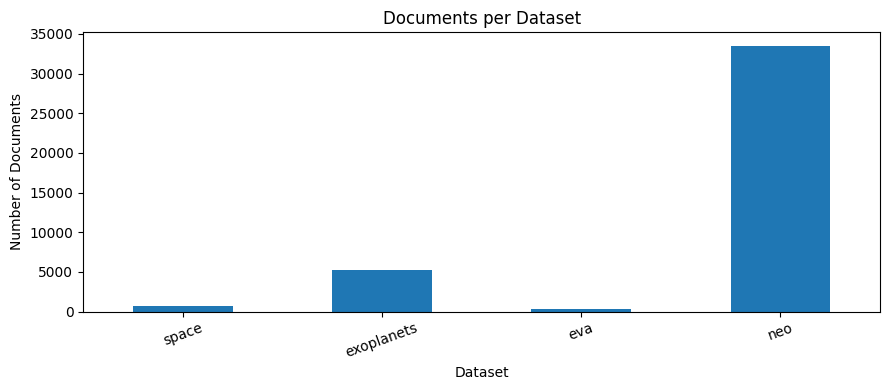

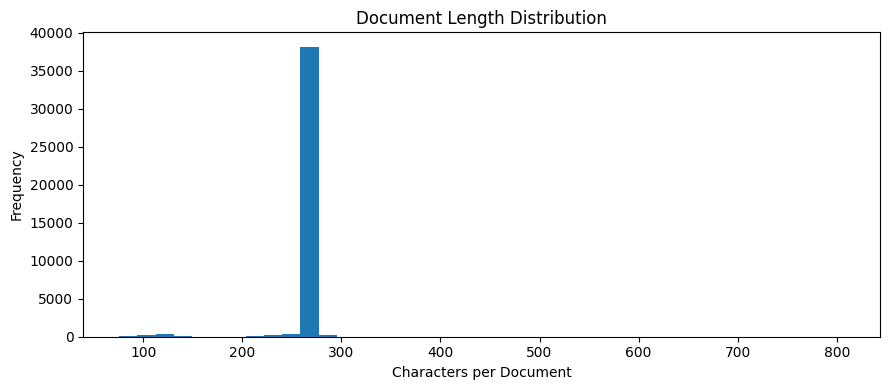

Total documents: 39,886
Total corpus characters: 10,630,617


In [9]:
source_counts = pd.Series({
    name: len(data)
    for name, data in selected_datasets.items()
})

source_summary = pd.DataFrame({
    "Documents": source_counts,
    "Percentage": (source_counts / source_counts.sum()) * 100
})

display(source_summary.round(2))

plt.figure(figsize=(9, 4))
source_counts.plot(kind="bar")
plt.title("Documents per Dataset")
plt.xlabel("Dataset")
plt.ylabel("Number of Documents")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.hist(document_lengths, bins=40)
plt.title("Document Length Distribution")
plt.xlabel("Characters per Document")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print(f"Total documents: {source_counts.sum():,}")
print(f"Total corpus characters: {len(text_corpus):,}")

# 10. Data Quality and Corpus Balancing

A language model learns patterns based on the frequency and distribution of its training data. If one dataset contributes most of the text, the model may become biased toward that subject.

Our current corpus contains four sources:

- Space-related questions and answers
- Exoplanet information
- Extravehicular activity (EVA) records
- Near-Earth Object (NEO) records

The NEO dataset represents approximately 84% of all documents. We will inspect the corpus for missing-value placeholders and consider a balanced training selection.

We will preserve the original datasets and create a separate training corpus so that data selection does not modify the source records.

In [10]:
def combine_values(value1, value2):
    parts = [clean_value(value1), clean_value(value2)]
    parts = [part for part in parts if part is not None]
    return " ".join(parts) if parts else None


def build_exoplanet_document(row):
    fields = {
        "Name": clean_value(row["name"]),
        "Planet type": clean_value(row["planet_type"]),
        "Distance": clean_value(row["distance"]),
        "Stellar magnitude": clean_value(row["stellar_magnitude"]),
        "Discovery year": clean_value(row["discovery_year"]),
        "Mass": combine_values(row["mass_multiplier"], row["mass_wrt"]),
        "Radius": combine_values(row["radius_multiplier"], row["radius_wrt"]),
        "Orbital radius": clean_value(row["orbital_radius"]),
        "Orbital period": clean_value(row["orbital_period"]),
        "Eccentricity": clean_value(row["eccentricity"]),
        "Detection method": clean_value(row["detection_method"])
    }

    return ". ".join(
        f"{key}: {value}"
        for key, value in fields.items()
        if value is not None
    )


exoplanet_documents = [
    build_exoplanet_document(row)
    for _, row in exoplanet_df.iterrows()
]

text_documents = (
    text_documents[:len(space_df)]
    + exoplanet_documents
    + text_documents[len(space_df) + len(exoplanet_df):]
)

cleaned_documents = [
    " ".join(document.split())
    for document in text_documents
    if document and document.strip()
]

text_corpus = "\n\n".join(cleaned_documents)
document_lengths = [len(doc) for doc in cleaned_documents]

invalid_terms = ["None None", "nan nan", "Mass: None", "Radius: None"]

for term in invalid_terms:
    print(f"{term}: {sum(term in doc for doc in cleaned_documents)} documents")

print(f"\nDocuments after correction: {len(cleaned_documents):,}")
print(f"Corpus characters: {len(text_corpus):,}")
print("\nCorrected exoplanet sample:")
print(exoplanet_documents[0])

None None: 0 documents
nan nan: 0 documents
Mass: None: 0 documents
Radius: None: 0 documents

Documents after correction: 39,886
Corpus characters: 10,503,903

Corrected exoplanet sample:
Name: 11 Comae Berenices b. Planet type: Gas Giant. Distance: 304. Stellar magnitude: 4.7231. Discovery year: 2007. Mass: 19.4 Jupiter. Radius: 1.08 Jupiter. Orbital radius: 1.29. Orbital period: 0.8925. Eccentricity: 0.23. Detection method: Radial Velocity


# 11. Creating a Balanced Training Corpus

The original corpus contains approximately 84% Near-Earth Object records. Training directly on this distribution could cause the model to favour asteroid-related information.

To reduce this imbalance, we will create a balanced selection for training.

We will:
- Retain all space question-answer records.
- Retain all exoplanet records.
- Retain all EVA records.
- Randomly select a representative subset of NEO records.
- Shuffle the selected documents before tokenization.

The original datasets and complete corpus remain unchanged. Only the training selection will be reduced.

This approach gives the smaller subject areas a stronger presence during training while preserving a meaningful amount of NEO information.

In [11]:
random.seed(42)

space_documents = text_documents[:len(space_df)]

exoplanet_documents = text_documents[
    len(space_df):len(space_df) + len(exoplanet_df)
]

eva_start = len(space_df) + len(exoplanet_df)
eva_documents = text_documents[
    eva_start:eva_start + len(eva_df)
]

neo_documents = text_documents[
    eva_start + len(eva_df):
]

neo_sample_size = min(8000, len(neo_documents))

selected_neo_documents = random.sample(
    neo_documents,
    neo_sample_size
)

training_documents = (
    space_documents
    + exoplanet_documents
    + eva_documents
    + selected_neo_documents
)

random.shuffle(training_documents)

training_corpus = "\n\n".join(training_documents)

training_summary = pd.Series({
    "Space Q&A": len(space_documents),
    "Exoplanets": len(exoplanet_documents),
    "EVA": len(eva_documents),
    "Near-Earth Objects": len(selected_neo_documents)
})

summary_df = pd.DataFrame({
    "Documents": training_summary,
    "Percentage": training_summary / training_summary.sum() * 100
})

display(summary_df.round(2))

print(f"Total training documents: {len(training_documents):,}")
print(f"Training corpus characters: {len(training_corpus):,}")
print(f"Original corpus characters: {len(text_corpus):,}")

,Documents,Percentage
Space Q&A,748,5.20
Exoplanets,5250,36.53
EVA,374,2.60
Near-Earth Objects,8000,55.66


Total training documents: 14,372
Training corpus characters: 3,639,275
Original corpus characters: 10,503,903


# 12. Tokenization

A language model cannot directly understand raw text. It processes numerical representations called tokens.

For Stallaris, we will build a custom character-level tokenizer from the training corpus.

The tokenizer will:
- Identify every unique character in the corpus.
- Assign each character a unique integer ID.
- Convert text into sequences of integer IDs.
- Convert generated integer IDs back into readable text.
- Use dedicated IDs for padding and unknown characters.

We are building this tokenizer from scratch rather than using a pretrained tokenizer.

Character-level tokenization is simple and allows the model to learn spelling, punctuation, and text patterns directly. However, it generally requires longer sequences than word-level or subword tokenization.

In [12]:
class CharacterTokenizer:
    def __init__(self, text):
        self.pad_token = "<PAD>"
        self.unk_token = "<UNK>"

        characters = sorted(set(text))

        self.vocab = [self.pad_token, self.unk_token] + characters
        self.stoi = {character: index for index, character in enumerate(self.vocab)}
        self.itos = {index: character for character, index in self.stoi.items()}

        self.pad_token_id = self.stoi[self.pad_token]
        self.unk_token_id = self.stoi[self.unk_token]

    def encode(self, text):
        return [
            self.stoi.get(character, self.unk_token_id)
            for character in text
        ]

    def decode(self, token_ids):
        return "".join(
            self.itos.get(token_id, self.unk_token)
            for token_id in token_ids
            if token_id != self.pad_token_id
        )

    @property
    def vocab_size(self):
        return len(self.vocab)


tokenizer = CharacterTokenizer(training_corpus)

encoded_sample = tokenizer.encode(training_documents[0])
decoded_sample = tokenizer.decode(encoded_sample)

print(f"Vocabulary size: {tokenizer.vocab_size}")
print(f"Padding token ID: {tokenizer.pad_token_id}")
print(f"Unknown token ID: {tokenizer.unk_token_id}")
print(f"\nOriginal text:\n{training_documents[0][:300]}")
print(f"\nEncoded sample:\n{encoded_sample[:80]}")
print(f"\nDecoded text:\n{decoded_sample[:300]}")
print(f"\nEncoding and decoding match: {decoded_sample == training_documents[0]}")

Vocabulary size: 90
Padding token ID: 0
Unknown token ID: 1

Original text:
Near-Earth object information. Object ID: 3827156. Object name: (2018 RL). Absolute magnitude: 19.86. Minimum diameter: 0.2835. Maximum diameter: 0.6339. Orbiting body: Earth. Relative velocity: 40374.9385. Miss distance: 49438274.0488. Potentially hazardous: False.

Encoded sample:
[42, 59, 55, 72, 14, 33, 55, 72, 74, 62, 3, 69, 56, 64, 59, 57, 74, 3, 63, 68, 60, 69, 72, 67, 55, 74, 63, 69, 68, 15, 3, 43, 56, 64, 59, 57, 74, 3, 37, 32, 27, 3, 20, 25, 19, 24, 18, 22, 23, 15, 3, 43, 56, 64, 59, 57, 74, 3, 68, 55, 67, 59, 27, 3, 9, 19, 17, 18, 25, 3, 46, 40, 10, 15, 3, 29, 56, 73, 69, 66]

Decoded text:
Near-Earth object information. Object ID: 3827156. Object name: (2018 RL). Absolute magnitude: 19.86. Minimum diameter: 0.2835. Maximum diameter: 0.6339. Orbiting body: Earth. Relative velocity: 40374.9385. Miss distance: 49438274.0488. Potentially hazardous: False.

Encoding and decoding match: True


# 13. Encoding the Training Corpus

The tokenizer is ready. We will now convert the complete balanced training corpus into integer token IDs.

This numerical representation is the actual input format required by our PyTorch model.

We will also inspect:
- Total number of tokens.
- Vocabulary size.
- Number of tokens per document.
- A small encoded sample.

The resulting token sequence will later be divided into fixed-length context windows for next-character prediction.

In [13]:
encoded_documents = [
    tokenizer.encode(document)
    for document in training_documents
]

all_token_ids = [
    token_id
    for document in encoded_documents
    for token_id in document
]

print(f"Number of documents: {len(encoded_documents):,}")
print(f"Total tokens: {len(all_token_ids):,}")
print(f"Vocabulary size: {tokenizer.vocab_size}")
print(f"Average tokens per document: {np.mean([len(doc) for doc in encoded_documents]):.2f}")
print(f"Shortest document: {min(len(doc) for doc in encoded_documents)} tokens")
print(f"Longest document: {max(len(doc) for doc in encoded_documents)} tokens")

print("\nEncoded document sample:")
print(encoded_documents[0][:100])

Number of documents: 14,372
Total tokens: 3,610,533
Vocabulary size: 90
Average tokens per document: 251.22
Shortest document: 76 tokens
Longest document: 812 tokens

Encoded document sample:
[42, 59, 55, 72, 14, 33, 55, 72, 74, 62, 3, 69, 56, 64, 59, 57, 74, 3, 63, 68, 60, 69, 72, 67, 55, 74, 63, 69, 68, 15, 3, 43, 56, 64, 59, 57, 74, 3, 37, 32, 27, 3, 20, 25, 19, 24, 18, 22, 23, 15, 3, 43, 56, 64, 59, 57, 74, 3, 68, 55, 67, 59, 27, 3, 9, 19, 17, 18, 25, 3, 46, 40, 10, 15, 3, 29, 56, 73, 69, 66, 75, 74, 59, 3, 67, 55, 61, 68, 63, 74, 75, 58, 59, 27, 3, 18, 26, 15, 25, 23]


# 14. Training and Validation Split

Before training, we divide the encoded documents into two separate groups.

- Training set (90%): Used by the model to learn character patterns and predict subsequent tokens.
- Validation set (10%): Used to evaluate the model on documents it did not train on.

We split at the document level rather than randomly splitting individual characters. This prevents parts of the same document from appearing in both sets.

The training set will update the model's parameters, while the validation set will help us monitor generalization and detect overfitting.

In [14]:
random.seed(42)

shuffled_documents = encoded_documents.copy()
random.shuffle(shuffled_documents)

split_index = int(len(shuffled_documents) * 0.90)

train_documents = shuffled_documents[:split_index]
val_documents = shuffled_documents[split_index:]

train_tokens = [
    token_id
    for document in train_documents
    for token_id in document
]

val_tokens = [
    token_id
    for document in val_documents
    for token_id in document
]

print(f"Training documents: {len(train_documents):,}")
print(f"Validation documents: {len(val_documents):,}")

print(f"\nTraining tokens: {len(train_tokens):,}")
print(f"Validation tokens: {len(val_tokens):,}")

print(
    f"\nTraining percentage: "
    f"{len(train_documents) / len(encoded_documents) * 100:.2f}%"
)

print(
    f"Validation percentage: "
    f"{len(val_documents) / len(encoded_documents) * 100:.2f}%"
)

Training documents: 12,934
Validation documents: 1,438

Training tokens: 3,248,891
Validation tokens: 361,642

Training percentage: 89.99%
Validation percentage: 10.01%


# 15. Sliding-Window Context Preparation

A Transformer language model learns by predicting the next token from a sequence of previous tokens.

We will use a sliding-window approach to create training examples.

Each example contains:
- An input sequence of a fixed context length.
- A target sequence shifted one position to the right.

For example, with a context length of 5:

Input:  [A, B, C, D, E]

Target: [B, C, D, E, F]

The model learns to predict the next character at every position in the input sequence.

We will use a context length of 128 tokens. This allows the model to learn local relationships without requiring excessively large memory.

In [15]:
CONTEXT_LENGTH = 128

def create_sequences(token_ids, context_length):
    inputs = []
    targets = []

    for start in range(0, len(token_ids) - context_length, context_length):
        chunk = token_ids[start:start + context_length + 1]

        inputs.append(chunk[:-1])
        targets.append(chunk[1:])

    return torch.tensor(inputs, dtype=torch.long), torch.tensor(targets, dtype=torch.long)


X_train, Y_train = create_sequences(train_tokens, CONTEXT_LENGTH)
X_val, Y_val = create_sequences(val_tokens, CONTEXT_LENGTH)

print("Training sequence shapes:")
print(f"Inputs:  {X_train.shape}")
print(f"Targets: {Y_train.shape}")

print("\nValidation sequence shapes:")
print(f"Inputs:  {X_val.shape}")
print(f"Targets: {Y_val.shape}")

print("\nFirst training example:")
print("Input: ", X_train[0][:10].tolist())
print("Target:", Y_train[0][:10].tolist())

print(
    "\nShift verification:",
    torch.equal(X_train[0, 1:], Y_train[0, :-1])
)

Training sequence shapes:
Inputs:  torch.Size([25381, 128])
Targets: torch.Size([25381, 128])

Validation sequence shapes:
Inputs:  torch.Size([2825, 128])
Targets: torch.Size([2825, 128])

First training example:
Input:  [33, 78, 74, 72, 55, 76, 59, 62, 63, 57]
Target: [78, 74, 72, 55, 76, 59, 62, 63, 57, 75]

Shift verification: True


# 16. PyTorch Dataset and DataLoader

We now have fixed-length input and target sequences. The next step is to prepare them for efficient training.

PyTorch provides two useful components:

- Dataset: Stores the input and target sequence pairs and retrieves individual examples.
- DataLoader: Groups examples into batches and optionally shuffles their order.

We will use a batch size of 32 initially.

Batch processing allows the model to process multiple sequences simultaneously, improving computational efficiency and making better use of the available GPU.

In [16]:
class LanguageModelDataset(Dataset):
    def __init__(self, inputs, targets):
        self.inputs = inputs
        self.targets = targets

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, index):
        return self.inputs[index], self.targets[index]


BATCH_SIZE = 32

train_dataset = LanguageModelDataset(X_train, Y_train)
val_dataset = LanguageModelDataset(X_val, Y_val)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False
)

sample_inputs, sample_targets = next(iter(train_loader))

print(f"Training batches: {len(train_loader):,}")
print(f"Validation batches: {len(val_loader):,}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Input batch shape: {sample_inputs.shape}")
print(f"Target batch shape: {sample_targets.shape}")
print(f"Input data type: {sample_inputs.dtype}")
print(f"Target data type: {sample_targets.dtype}")

Training batches: 793
Validation batches: 89
Batch size: 32
Input batch shape: torch.Size([32, 128])
Target batch shape: torch.Size([32, 128])
Input data type: torch.int64
Target data type: torch.int64


# 17. Decoder-Only Transformer Architecture

We will build Stallaris using a decoder-only Transformer architecture in PyTorch.

Unlike an encoder-decoder Transformer, a decoder-only model predicts the next token using only the preceding context.

Our architecture consists of:

1. Token Embedding: Converts token IDs into dense numerical vectors.
2. Positional Embedding: Adds information about token positions.
3. Causal Self-Attention: Allows each position to attend only to previous positions and itself.
4. Feed-Forward Network: Processes the attention output through nonlinear transformations.
5. Residual Connections and Layer Normalization: Improve training stability and information flow.
6. Language Model Head: Converts the final hidden representation into vocabulary-sized prediction scores.

Initial architecture configuration:

- Embedding dimension: 128
- Attention heads: 4
- Transformer blocks: 2
- Feed-forward dimension: 512
- Context length: 128
- Dropout: 0.1

The model will be implemented from scratch using PyTorch building blocks rather than loading a pretrained model.

In [17]:
MODEL_CONFIG = {
    "vocab_size": tokenizer.vocab_size,
    "context_length": CONTEXT_LENGTH,
    "d_model": 128,
    "num_heads": 4,
    "num_layers": 2,
    "ffn_dim": 512,
    "dropout": 0.1
}

assert MODEL_CONFIG["d_model"] % MODEL_CONFIG["num_heads"] == 0

for key, value in MODEL_CONFIG.items():
    print(f"{key}: {value}")

total_parameters = sum(
    p.numel() for p in nn.Linear(1, 1).parameters()
)

print("\nHead dimension:", MODEL_CONFIG["d_model"] // MODEL_CONFIG["num_heads"])
print("Configuration is valid.")

vocab_size: 90
context_length: 128
d_model: 128
num_heads: 4
num_layers: 2
ffn_dim: 512
dropout: 0.1

Head dimension: 32
Configuration is valid.


# 18. Token and Positional Embeddings

Transformers operate on numerical vectors rather than raw token IDs.

We will use two embedding layers:

**1. Token Embedding**

Maps each token ID to a trainable vector of 128 dimensions. During training, the model learns meaningful numerical representations for the characters in our vocabulary.

**2. Positional Embedding**

Provides information about the position of each token in the input sequence. Without positional information, the Transformer would not inherently know the order of characters.

The two embeddings are added together to create the initial representation passed into the Transformer blocks.

We will implement both using PyTorch's `nn.Embedding` layer.

In [18]:
class TokenPositionEmbedding(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.token_embedding = nn.Embedding(
            config["vocab_size"],
            config["d_model"]
        )

        self.position_embedding = nn.Embedding(
            config["context_length"],
            config["d_model"]
        )

        self.dropout = nn.Dropout(config["dropout"])

    def forward(self, token_ids):
        batch_size, sequence_length = token_ids.shape

        positions = torch.arange(
            sequence_length,
            device=token_ids.device
        )

        token_vectors = self.token_embedding(token_ids)
        position_vectors = self.position_embedding(positions)

        embeddings = token_vectors + position_vectors

        return self.dropout(embeddings)


embedding_layer = TokenPositionEmbedding(MODEL_CONFIG).to(DEVICE)

sample_batch = sample_inputs[:4].to(DEVICE)
embedding_output = embedding_layer(sample_batch)

print("Input shape:", sample_batch.shape)
print("Embedding output shape:", embedding_output.shape)
print("Embedding dimension:", MODEL_CONFIG["d_model"])
print("Device:", embedding_output.device)

Input shape: torch.Size([4, 128])
Embedding output shape: torch.Size([4, 128, 128])
Embedding dimension: 128
Device: cpu


# 19. Causal Self-Attention

Self-attention allows each token to examine other tokens in its input sequence and determine which positions are useful for understanding its context.

For an autoregressive language model, we must prevent a token from looking at future tokens.

We achieve this using a causal attention mask.

The mask ensures:
- The first token can attend only to itself.
- The second token can attend to the first and second tokens.
- Later tokens can attend to all preceding tokens and themselves.
- No token can access future positions.

We will implement multi-head causal self-attention.

Our model uses four attention heads. Each head independently learns relationships between tokens, allowing the model to capture different contextual patterns.

The attention mechanism uses Query, Key, and Value projections to calculate how information flows between positions.

In [19]:
class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.num_heads = config["num_heads"]
        self.head_dim = config["d_model"] // self.num_heads

        self.qkv = nn.Linear(config["d_model"], 3 * config["d_model"])
        self.projection = nn.Linear(config["d_model"], config["d_model"])

        self.dropout = nn.Dropout(config["dropout"])

        self.register_buffer(
            "causal_mask",
            torch.tril(torch.ones(
                config["context_length"],
                config["context_length"]
            ))
        )

    def forward(self, x):
        batch_size, sequence_length, d_model = x.shape

        q, k, v = self.qkv(x).chunk(3, dim=-1)

        q = q.view(batch_size, sequence_length, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.view(batch_size, sequence_length, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.view(batch_size, sequence_length, self.num_heads, self.head_dim).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)

        mask = self.causal_mask[:sequence_length, :sequence_length]
        scores = scores.masked_fill(mask == 0, float("-inf"))

        attention = F.softmax(scores, dim=-1)
        attention = self.dropout(attention)

        output = attention @ v
        output = output.transpose(1, 2).contiguous().view(batch_size, sequence_length, d_model)

        return self.dropout(self.projection(output))


attention_layer = CausalSelfAttention(MODEL_CONFIG).to(DEVICE)
attention_output = attention_layer(embedding_output)

print("Attention input shape:", embedding_output.shape)
print("Attention output shape:", attention_output.shape)
print("Attention heads:", MODEL_CONFIG["num_heads"])
print("Head dimension:", MODEL_CONFIG["d_model"] // MODEL_CONFIG["num_heads"])

Attention input shape: torch.Size([4, 128, 128])
Attention output shape: torch.Size([4, 128, 128])
Attention heads: 4
Head dimension: 32


In [20]:
class TransformerBlock(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.attention_norm = nn.LayerNorm(config["d_model"])
        self.attention = CausalSelfAttention(config)

        self.ffn_norm = nn.LayerNorm(config["d_model"])
        self.feed_forward = nn.Sequential(
            nn.Linear(config["d_model"], config["ffn_dim"]),
            nn.GELU(),
            nn.Linear(config["ffn_dim"], config["d_model"]),
            nn.Dropout(config["dropout"])
        )

    def forward(self, x):
        x = x + self.attention(self.attention_norm(x))
        x = x + self.feed_forward(self.ffn_norm(x))
        return x


transformer_block = TransformerBlock(MODEL_CONFIG).to(DEVICE)
block_output = transformer_block(embedding_output)

print("Input shape:", embedding_output.shape)
print("Output shape:", block_output.shape)
print("Feed-forward dimension:", MODEL_CONFIG["ffn_dim"])
print("Transformer block test passed.")

Input shape: torch.Size([4, 128, 128])
Output shape: torch.Size([4, 128, 128])
Feed-forward dimension: 512
Transformer block test passed.


In [21]:
class StallarisTransformer(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.embedding = TokenPositionEmbedding(config)

        self.blocks = nn.Sequential(
            *[TransformerBlock(config) for _ in range(config["num_layers"])]
        )

        self.final_norm = nn.LayerNorm(config["d_model"])
        self.language_head = nn.Linear(
            config["d_model"],
            config["vocab_size"],
            bias=False
        )

    def forward(self, token_ids, targets=None):
        x = self.embedding(token_ids)
        x = self.blocks(x)
        x = self.final_norm(x)

        logits = self.language_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1)
            )

        return logits, loss


model = StallarisTransformer(MODEL_CONFIG).to(DEVICE)

parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

test_inputs = sample_inputs[:2].to(DEVICE)
test_targets = sample_targets[:2].to(DEVICE)

with torch.no_grad():
    test_logits, test_loss = model(test_inputs, test_targets)

print("Model:", model.__class__.__name__)
print("Logits shape:", test_logits.shape)
print("Initial test loss:", round(test_loss.item(), 4))
print(f"Trainable parameters: {parameter_count:,}")
print("Device:", DEVICE)

Model: StallarisTransformer
Logits shape: torch.Size([2, 128, 90])
Initial test loss: 4.6126
Trainable parameters: 436,224
Device: cpu


# 20. Training the Stallaris Model

The complete Transformer architecture is ready. We will now train it using next-token prediction.

During training:

1. The model receives a sequence of 128 characters.
2. It predicts the next character at each position.
3. Cross-entropy loss measures the difference between predictions and actual targets.
4. Backpropagation calculates gradients.
5. AdamW updates the model parameters.

We will also evaluate validation loss after each epoch to monitor generalization.

Gradient clipping will help prevent excessively large gradients, while a learning-rate scheduler will gradually reduce the learning rate during training.

In [22]:
from tqdm.auto import tqdm

EPOCHS = 5
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.01

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

train_losses = []
val_losses = []

for epoch in range(EPOCHS):
    model.train()
    total_train_loss = 0

    progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}")

    for inputs, targets in progress:
        inputs = inputs.to(DEVICE)
        targets = targets.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        _, loss = model(inputs, targets)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        optimizer.step()

        total_train_loss += loss.item()
        progress.set_postfix(loss=f"{loss.item():.4f}")

    average_train_loss = total_train_loss / len(train_loader)

    model.eval()
    total_val_loss = 0

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs = inputs.to(DEVICE)
            targets = targets.to(DEVICE)

            _, loss = model(inputs, targets)
            total_val_loss += loss.item()

    average_val_loss = total_val_loss / len(val_loader)

    train_losses.append(average_train_loss)
    val_losses.append(average_val_loss)

    scheduler.step()

    print(
        f"Epoch {epoch + 1}: "
        f"Train Loss = {average_train_loss:.4f}, "
        f"Validation Loss = {average_val_loss:.4f}, "
        f"Learning Rate = {scheduler.get_last_lr()[0]:.6f}"
    )

Epoch 1/5:   0%|          | 0/793 [00:00<?, ?it/s]

Epoch 1: Train Loss = 1.8207, Validation Loss = 0.8581, Learning Rate = 0.000271


Epoch 2/5:   0%|          | 0/793 [00:00<?, ?it/s]

Epoch 2: Train Loss = 0.8303, Validation Loss = 0.6277, Learning Rate = 0.000196


Epoch 3/5:   0%|          | 0/793 [00:00<?, ?it/s]

Epoch 3: Train Loss = 0.6824, Validation Loss = 0.5843, Learning Rate = 0.000104


Epoch 4/5:   0%|          | 0/793 [00:00<?, ?it/s]

Epoch 4: Train Loss = 0.6384, Validation Loss = 0.5674, Learning Rate = 0.000029


Epoch 5/5:   0%|          | 0/793 [00:00<?, ?it/s]

Epoch 5: Train Loss = 0.6224, Validation Loss = 0.5616, Learning Rate = 0.000000


In [23]:
print("Training Results")
print("-" * 40)

for epoch, (train_loss, val_loss) in enumerate(
    zip(train_losses, val_losses), start=1
):
    print(
        f"Epoch {epoch}: "
        f"Train Loss = {train_loss:.4f}, "
        f"Validation Loss = {val_loss:.4f}"
    )

final_train_loss = train_losses[-1]
final_val_loss = val_losses[-1]

print("\nFinal Metrics")
print("-" * 40)
print(f"Training Loss: {final_train_loss:.4f}")
print(f"Validation Loss: {final_val_loss:.4f}")
print(f"Training Perplexity: {math.exp(final_train_loss):.2f}")
print(f"Validation Perplexity: {math.exp(final_val_loss):.2f}")

Training Results
----------------------------------------
Epoch 1: Train Loss = 1.8207, Validation Loss = 0.8581
Epoch 2: Train Loss = 0.8303, Validation Loss = 0.6277
Epoch 3: Train Loss = 0.6824, Validation Loss = 0.5843
Epoch 4: Train Loss = 0.6384, Validation Loss = 0.5674
Epoch 5: Train Loss = 0.6224, Validation Loss = 0.5616

Final Metrics
----------------------------------------
Training Loss: 0.6224
Validation Loss: 0.5616
Training Perplexity: 1.86
Validation Perplexity: 1.75


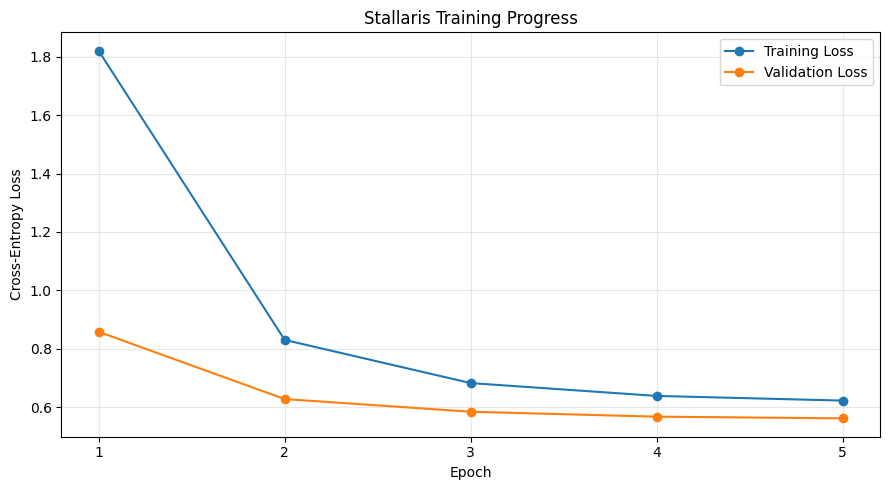

In [24]:
plt.figure(figsize=(9, 5))

plt.plot(train_losses, marker="o", label="Training Loss")
plt.plot(val_losses, marker="o", label="Validation Loss")

plt.title("Stallaris Training Progress")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.xticks(range(len(train_losses)), range(1, len(train_losses) + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
def generate_text(prompt, max_new_tokens=300, temperature=0.8, top_k=20):
    model.eval()

    tokens = torch.tensor(
        [tokenizer.encode(prompt)],
        dtype=torch.long,
        device=DEVICE
    )

    with torch.no_grad():
        for _ in range(max_new_tokens):
            context = tokens[:, -CONTEXT_LENGTH:]
            logits, _ = model(context)

            logits = logits[:, -1, :] / temperature

            if top_k is not None:
                values, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < values[:, [-1]]] = float("-inf")

            probabilities = F.softmax(logits, dim=-1)
            next_token = torch.multinomial(probabilities, num_samples=1)

            tokens = torch.cat((tokens, next_token), dim=1)

    return tokenizer.decode(tokens[0].tolist())




In [26]:
print("=" * 55)
print("          STALLARIS // DEEP SPACE TERMINAL")
print("          AI SYSTEM ONLINE")
print("=" * 55)
print("Stallaris is ready. Type 'quit' to disconnect.\n")

while True:
    user_message = input("You: ").strip()

    if user_message.lower() in ["quit", "exit"]:
        print("\n" + "=" * 55)
        print("STALLARIS: Transmission terminated.")
        print("Your signal fades beyond the event horizon...")
        print("Until the stars align again, Commander.")
        print("          SEE YOU AGAIN.")
        print("=" * 55)
        break

    if not user_message:
        continue

    prompt = f"Question: {user_message} Answer:"

    response = generate_text(
        prompt,
        max_new_tokens=200,
        temperature=0.8,
        top_k=20
    )

    answer = response[len(prompt):].strip()

    print(f"\nSTALLARIS: {answer}\n")

          STALLARIS // DEEP SPACE TERMINAL
          AI SYSTEM ONLINE
Stallaris is ready. Type 'quit' to disconnect.



You:  quit



STALLARIS: Transmission terminated.
Your signal fades beyond the event horizon...
Until the stars align again, Commander.
          SEE YOU AGAIN.
